# Error analysis: where a model fails

[Measuring a regression model's error](regression_metrics.ipynb) ended with a hint: the same average error can hide very different failures. Error analysis looks at the errors themselves instead of their average: which rows, which groups, which places, in which direction. Its purpose is practical: each pattern found is a candidate for the next feature, the next cleaning step, or the next model.

## A model and its errors

The gradient boosting model of [Gradient boosting](../algorithms/tree-based/gradient_boosting.ipynb), with early stopping, on California housing. The errors are studied on the **validation** rows, not the test rows: error analysis is part of building the model, since what it finds will change the model, and a test set used that way would stop being a test ([Validation and model selection](../ml-fundamentals/validation_and_model_selection.ipynb)).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True).frame
X = housing.drop(columns="MedHouseVal")
y = 100_000 * housing["MedHouseVal"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_validation, y_train, y_validation = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)

model = HistGradientBoostingRegressor(max_iter=2000, early_stopping=True, random_state=42).fit(X_train, y_train)
errors = X_validation.assign(true_value=y_validation, predicted=model.predict(X_validation))
errors["residual"] = errors["true_value"] - errors["predicted"]
errors["absolute_error"] = errors["residual"].abs()
errors[["true_value", "predicted", "residual", "absolute_error"]].describe().round(0)

,true_value,predicted,residual,absolute_error
count,4128.0,4128.0,4128.0,4128.0
mean,208356.0,208663.0,-308.0,31411.0
std,117194.0,107332.0,46787.0,34673.0
min,22500.0,38366.0,-327774.0,4.0
25%,119575.0,128103.0,-22591.0,9429.0
50%,180000.0,186126.0,-3657.0,20590.0
75%,267200.0,263010.0,17710.0,41367.0
max,500001.0,549967.0,365471.0,365471.0


The **residual** is the true value minus the prediction: positive where the model predicts too low, negative where it predicts too high. Its mean is the model's **bias**, how far off it is on average *in one direction*; the mean of its absolute value is the MAE.

The mean residual is about -\$300 on predictions that average \$208,000: overall, the model has no bias worth mentioning. Its MAE, the mean of the absolute errors, about \$31,400, is all spread, errors in both directions that cancel in the mean. The extremes are another matter: one district is predicted \$328,000 too high, another \$365,000 too low.

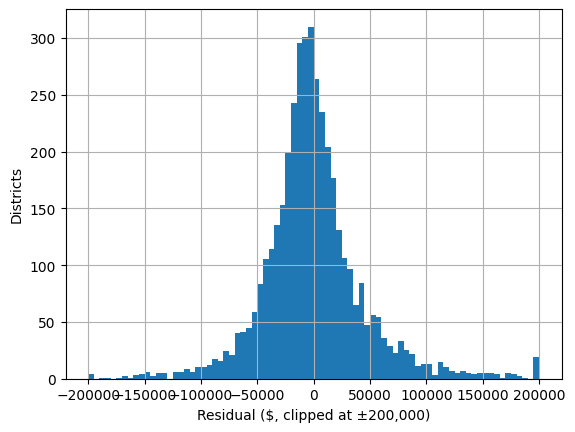

In [ ]:
import matplotlib.pyplot as plt

errors["residual"].clip(-200_000, 200_000).hist(bins=80)
plt.xlabel("Residual ($, clipped at ±200,000)")
plt.ylabel("Districts")
plt.show()

Most residuals lie within ±\$50,000, in a peak around 0 that is slightly asymmetric: a longer tail of large positive residuals, districts predicted far too low.

## By group

Splitting the rows into groups and computing the bias and the MAE of each finds failures that the overall numbers average away. The count of each group says how much to trust its numbers. By bands of income, the strongest feature:

In [ ]:
def by_group(groups):
    return errors.groupby(groups, observed=True).agg(
        districts=("residual", "size"), bias=("residual", "mean"), MAE=("absolute_error", "mean")).round(0)


by_group(pd.qcut(errors["MedInc"], 5).rename("income band"))

,districts,bias,MAE
income band,,,
"(0.499, 2.382]",826,1062.0,24649.0
"(2.382, 3.144]",827,-861.0,30432.0
"(3.144, 3.98]",824,-1032.0,30667.0
"(3.98, 5.181]",825,-158.0,33341.0
"(5.181, 15.0]",826,-551.0,37968.0


The bias stays within about \$1,000 in every band: the model is not systematically wrong for poor or rich districts. Its MAE grows with income, from about \$25,000 to \$38,000, because richer districts are more expensive and so vary more; in proportion, as [Measuring a regression model's error](regression_metrics.ipynb#the-same-errors-by-price) showed, the cheap districts fare worst.

## By the target

Grouping by the *true* value shows where the predictions are pulled. The last band is the districts at the cap of \$500,000 seen in [California housing, step by step](../basic-workflows/california_by_hand.ipynb), whose true value is only known to be at least that:

In [ ]:
value_band = pd.cut(errors["true_value"], bins=[0, 100_000, 200_000, 300_000, 400_000, 499_999, np.inf],
                    labels=["below 100k", "100–200k", "200–300k", "300–400k", "400–500k", "capped at 500k"])
by_group(value_band.rename("true value"))

,districts,bias,MAE
true value,,,
below 100k,731,-16880.0,20704.0
100–200k,1643,-10100.0,24689.0
200–300k,965,1145.0,33619.0
300–400k,414,15906.0,45543.0
400–500k,164,63370.0,71304.0
capped at 500k,211,45403.0,52008.0


Here the bias is anything but small. Districts worth less than \$100,000 are predicted about \$17,000 too high on average, and districts worth \$400,000 to \$500,000 about \$63,000 too low: the predictions are pulled towards the middle. The capped districts are predicted \$45,000 below a value that is itself only a lower bound.

Grouping by the true value has a trap, though. Any model whose errors are partly noise shows this pattern, even one that is right on average, because the districts with the highest true values are, among other things, the ones whose value happened to be higher than their features suggest. The fair question for systematic bias is the other one: *when the model predicts a value, is it right on average?* Grouped by the prediction instead:

In [ ]:
predicted_band = pd.cut(errors["predicted"], bins=[-np.inf, 100_000, 200_000, 300_000, 400_000, np.inf],
                        labels=["below 100k", "100–200k", "200–300k", "300–400k", "above 400k"])
by_group(predicted_band.rename("predicted value"))

,districts,bias,MAE
predicted value,,,
below 100k,565,1724.0,15067.0
100–200k,1728,-701.0,25156.0
200–300k,1070,-902.0,39632.0
300–400k,448,-2955.0,51896.0
above 400k,317,3962.0,37937.0


By the prediction, the bias is within about \$4,000 in every band: when the model says \$350,000, the districts it says it for are worth about that on average. The model is well **calibrated**. The pull towards the middle in the previous table is not a defect of this model but a consequence of grouping by the true value, which selects the districts where the noise happened to push the value up or down. Both tables are useful, for different questions: the first, to know whose values the model underestimates; the second, to know whether its predictions can be taken at face value.

## On the map

Each validation district at its position, coloured by its residual: red where the model predicts too low, blue where it predicts too high:

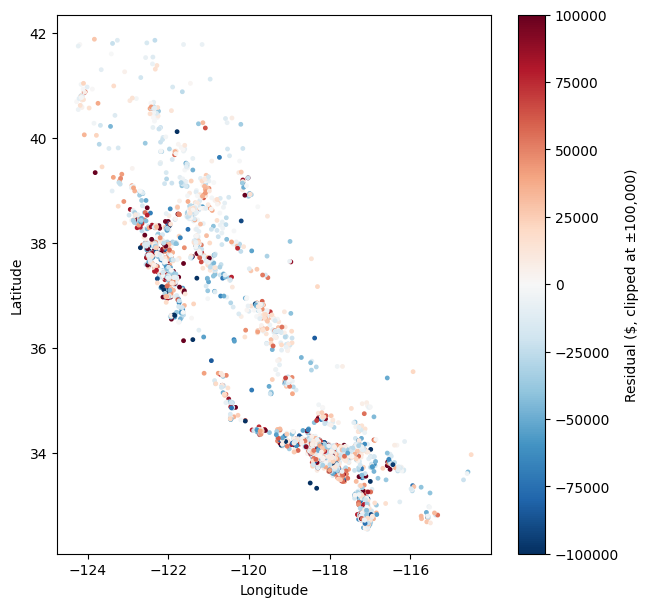

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(errors["Longitude"], errors["Latitude"], c=errors["residual"].clip(-100_000, 100_000),
            cmap="RdBu_r", s=6, vmin=-100_000, vmax=100_000)
plt.colorbar(label="Residual ($, clipped at ±100,000)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

The map doesn't show a region the model consistently gets wrong in one direction. It shows where the errors are *large*: in the dense coastal areas, the San Francisco Bay Area around latitude 38 and the Los Angeles area around latitude 34, dark red and dark blue sit side by side, while inland districts are pale. In a city, neighbouring districts can differ in value by hundreds of thousands of dollars, and eight numbers per district, two of them coordinates, can't describe a neighbourhood that finely.

## The largest errors

Finally, the rows themselves. The ten largest errors, with their features:

In [ ]:
errors.nlargest(10, "absolute_error")[["MedInc", "HouseAge", "AveRooms", "AveOccup", "Population",
                                         "Latitude", "Longitude", "true_value", "predicted"]].round(1)

,MedInc,HouseAge,AveRooms,AveOccup,Population,Latitude,Longitude,true_value,predicted
89,1.2,52.0,2.9,4.7,396.0,37.8,-122.3,500001.0,134530.2
1914,1.9,33.0,141.9,2.7,30.0,38.9,-120.1,500001.0,147903.6
15705,2.7,52.0,3.1,1.5,1202.0,37.8,-122.4,87500.0,415274.5
16556,3.7,6.0,4.6,2.9,69.0,37.8,-121.3,475000.0,161184.2
489,3.0,48.0,4.7,3.6,1656.0,37.9,-122.2,489600.0,176839.9
20443,3.3,50.0,5.3,3.7,130.0,34.3,-118.8,500001.0,209578.5
20322,2.6,8.0,3.0,1.3,102.0,34.2,-119.1,500001.0,224439.3
10758,5.4,4.0,5.1,1.9,1326.0,33.6,-117.9,500001.0,227886.1
1633,2.4,20.0,6.3,2.1,31.0,37.9,-122.2,475000.0,242359.9
9168,2.0,2.0,5.7,1.4,233.0,34.4,-118.6,450000.0,223410.1


Nine of the ten largest errors are districts worth \$450,000 or more, five of them at the cap, predicted at \$130,000 to \$250,000: three in the Bay Area (latitude 37.8–37.9, longitude about -122.3), four in southern California between Ventura County and Newport Beach, one near Stockton and one by Lake Tahoe. They are expensive places whose features, a modest median income or old houses, look like those of cheap ones. The tenth is the opposite: a district of central San Francisco worth \$87,500 and predicted at \$415,000. One district has 141.9 rooms per household for 30 people, the impossible-looking average met in [California housing, step by step](../basic-workflows/california_by_hand.ipynb); at latitude 38.9 and longitude -120.1 it is by Lake Tahoe, most likely holiday homes whose owners live elsewhere, so that the few resident households share many rooms. Several of the ten are small, with 30 to 130 people, where a median over a few households is itself noisy.

## From findings to the next step

Each finding suggests something to try, and each try is measured on the validation rows, like any other change:

| Finding | Next step to try |
| --- | --- |
| The capped districts are predicted far too low, and their true value is unknown | exclude them from training, and report them apart: the model can't learn a value the data doesn't contain |
| The largest errors, in both directions, are in the dense coastal areas | features that describe the neighbourhood more finely: clusters of coordinates (*clusters as features*, in the topic Unsupervised learning *(coming)*), distance to the coast |
| Some of the largest errors are districts with impossible-looking averages | check them as data problems before treating them as modelling problems |
| The error grows with the value | judge the model by percentage errors as well ([Measuring a regression model's error](regression_metrics.ipynb#errors-in-proportion-to-the-value)), or model the logarithm of the value |

The first is quick to try. The same model, trained without the capped districts, measured on the validation districts below the cap:

In [ ]:
from sklearn.metrics import mean_absolute_error

below_cap_train = y_train < 500_000
below_cap_validation = (y_validation < 500_000).to_numpy()
without_capped = HistGradientBoostingRegressor(max_iter=2000, early_stopping=True, random_state=42).fit(
    X_train[below_cap_train], y_train[below_cap_train])
{
    "trained with the capped districts": mean_absolute_error(y_validation[below_cap_validation], errors["predicted"][below_cap_validation]),
    "trained without them": mean_absolute_error(y_validation[below_cap_validation], without_capped.predict(X_validation[below_cap_validation])),
}

{'trained with the capped districts': 30301.39608088049,
 'trained without them': 29541.777129570713}

Trained without the capped districts, the model's error on the districts below the cap falls from about \$30,300 to \$29,500. The capped values were teaching it something false, that these districts are worth exactly \$500,001, and removing them helps on all the others. The price is that the new model says nothing reliable about districts above \$500,000, which the old one didn't either, but now that is explicit. Whether that trade is acceptable depends on what the predictions are for, which is the kind of decision error analysis exists to bring up.

California has no dates, but for data that changes over time the same analysis by period is often the most revealing of all: a model that fails increasingly on recent rows is learning a world that no longer exists. [King County: temporal leakage](https://github.com/avidaldo/king-county/blob/master/03-temporal_leakage.ipynb) shows it on house sales.